# Supplementary Fig. 10: Effect sizes of delta-rule consistent neural value updating across sessions

[AI generated summary] In each session, the neural value of the next trial is predicted from the neural value of the current trial and the outcome, with a linear regression $V(t+1) = \beta_0 + \beta_1 V(t) + \beta_2 R + \beta_3 V(t) R$ (neural value measured during task engagement, z-scored within session). Session-wise distributions of the GLM parameters, per monkey and area:
- **Supplementary Fig. 10a**: slope of the $V(t)$ regressor for positive outcomes ($\beta_1 + \beta_3$); filled dots: 95% confidence interval within [0, 1].
- **Supplementary Fig. 10b**: slope for negative outcomes ($\beta_1$); filled dots as in a.
- **Supplementary Fig. 10c**: intercept difference between positive and negative outcomes ($\beta_2$); filled dots: one-sided Wald test of $\beta_2 > 0$, p < 0.05.

The same GLM gives the number of delta-rule consistent sessions reported in the text (see `fig4cdef_neural_value.ipynb`). **How to run:** run all cells (less than a minute). Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/population_decoding/behav_neural_value` (see the README). To recompute them, run in this folder: `python run_neural_value_all_sessions.py` (several hours on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
from helpers_analysis import *
from helpers_delta_rule import plot_betas, plot_intercept_differences
from popy.config import RESULTS_PATH

# Raincloud plot of beta distributions per monkey and area

plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Load data

In [3]:
behav_new = pd.read_pickle(os.path.join(RESULTS_PATH, 'population_decoding', 'behav_neural_value', 'behav.pkl'))
#behav_new = behav_new.loc[behav_new.subregion=='dLPFC']
# remove 5% outliers from dV
#behav_new = behav_new.loc[behav_new['V_t'].abs() < behav_new['V_t'].abs().quantile(0.95)]
behav_new = behav_new.dropna()

In [4]:
# normalize dV and V_t per monkey, session, subregion
for time_interval in [(-4, -2), (1.5, 3.5)]:
    behav_new[f'V_t_{time_interval[0]}_{time_interval[1]}'] = behav_new.groupby(['monkey', 'session', 'subregion'])[f'V_t_{time_interval[0]}_{time_interval[1]}'].transform(lambda x: (x - x.mean()) / x.std())
    behav_new[f'V_t_p1_{time_interval[0]}_{time_interval[1]}'] = behav_new.groupby(['monkey', 'session', 'subregion'])[f'V_t_p1_{time_interval[0]}_{time_interval[1]}'].transform(lambda x: (x - x.mean()) / x.std())
    behav_new[f'dV_{time_interval[0]}_{time_interval[1]}'] = behav_new[f'V_t_p1_{time_interval[0]}_{time_interval[1]}'] - behav_new[f'V_t_{time_interval[0]}_{time_interval[1]}']

behav_new

,monkey,session,subregion,trial_id,block_id,best_target,target,feedback,switch,stay_value,...,target_1,V_t_-4_-2,V_t_p1_-4_-2,dV_-4_-2,V_t_behav,V_t_p1_behav,dV_behav,V_t_1.5_3.5,V_t_p1_1.5_3.5,dV_1.5_3.5
0,ka,230720,MCC,8,0,2,3.0,0.0,1.0,0.283056,...,False,-0.769454,0.812984,1.582438,0.283056,0.069825,-0.213231,-0.907589,-0.853688,0.053901
1,ka,230720,MCC,9,0,2,2.0,0.0,1.0,0.069825,...,False,0.811088,-0.362970,-1.174057,0.069825,0.069825,0.000000,-0.848967,-0.447462,0.401505
2,ka,230720,MCC,10,0,2,3.0,1.0,1.0,0.069825,...,False,-0.366271,-0.989564,-0.623293,0.069825,0.479459,0.409634,-0.443023,0.466314,0.909337
3,ka,230720,MCC,11,0,2,3.0,0.0,0.0,0.479459,...,False,-0.993615,-0.409184,0.584431,0.479459,0.283056,-0.196402,0.470115,-0.653801,-1.123917
4,ka,230720,MCC,12,0,2,3.0,0.0,0.0,0.283056,...,False,-0.412541,-0.424657,-0.012115,0.283056,0.167107,-0.115949,-0.649219,0.241101,0.890320
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66350,po,200722,dLPFC,372,8,1,1.0,0.0,0.0,0.723918,...,True,1.174154,1.031969,-0.142184,0.723918,0.503993,-0.219925,1.895587,-0.036211,-1.931798
66351,po,200722,dLPFC,373,8,1,1.0,1.0,0.0,0.503993,...,True,1.031827,0.190688,-0.841139,0.503993,0.654679,0.150686,-0.031474,1.038479,1.069952
66352,po,200722,dLPFC,374,8,1,1.0,1.0,0.0,0.654679,...,True,0.188484,0.597062,0.408579,0.654679,0.759587,0.104908,1.041053,0.686407,-0.354646
66353,po,200722,dLPFC,375,8,1,1.0,1.0,0.0,0.759587,...,True,0.595854,1.160500,0.564645,0.759587,0.832624,0.073037,0.689690,1.174502,0.484812


---
# GLM of the neural value update in each session

In [5]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

alpha = 0.05  # significance level

# -----------------------------
# Pick time window & session
# -----------------------------
time_interval = (1.5, 3.5)  # time window for V_t and V_t+1
behav_new['V_t']    = behav_new[f'V_t_{time_interval[0]}_{time_interval[1]}']
behav_new['V_t_p1'] = behav_new[f'V_t_p1_{time_interval[0]}_{time_interval[1]}']

res = []  # if not yet defined

for (monkey, session, subregion), behav_new_temp in behav_new.groupby(['monkey', 'session', 'subregion']):

    # Extract datapoints (FILTERED)
    V_t = behav_new_temp['V_t'].values
    V_t1 = behav_new_temp['V_t_p1'].values
    fb_vector = behav_new_temp['feedback'].values

    # create a dataframe, column A is V_t1, B is V_t, C is fb_vector
    data_temp = pd.DataFrame({
        'A': V_t1,
        'B': V_t,
        'C': fb_vector
    })

    results_mixed = fit_mixed_glm(data_temp)
    test_results = stat_tests_mixed_glm(results_mixed)
    hypothesis = add_hypothesis(test_results)

    # -----------------------------
    # Package per-session results (trimmed)
    # -----------------------------
    session_result = {
        'monkey': monkey,
        'session': session,
        'subregion': subregion,

        # mean(Vt+1) comparison
        #'mean_vt1_pos': mean_vt1_pos,
        #'mean_vt1_neg': mean_vt1_neg,
        #'p_neg_mean_lt_pos': p_neg_mean_lt_pos,

        # regression summaries
        #'slope_all': slope_all,
        #'intercept_all': intercept_all,
        #'r2_all': np.nan if np.isnan(r_all) else r_all**2,
        #'p_model_all': p_all,          # slope 2-sided p in simple LR

        'slope_pos': test_results['slope_c1'],
        'intercept_pos': test_results['intercept_c1'],
        #'r2_pos': np.nan if np.isnan(r_pos) else r_pos**2,
        'slope_pos_nonzero': test_results['b1_c1_significant'],          # slope 2-sided p in simple LR
        'slope_pos_withinbounds': test_results['b1_c1_within_bounds'],          # slope 2-sided p in simple LR

        'slope_neg': test_results['slope_c0'],
        'intercept_neg': test_results['intercept_c0'],
        #'r2_neg': np.nan if np.isnan(r_neg) else r_neg**2,
        'slope_neg_nonzero': test_results['b1_c0_significant'],          # slope 2-sided p in simple LR
        'slope_neg_withinbounds': test_results['b1_c0_within_bounds'],          # slope 2-sided p in simple LR

        # intercept higher
        'intercept_pos_higher': test_results['intercept_c1_higher'],

        # Add hypothesis
        'hypothesis': hypothesis,

        # one-tailed tests for slope constraints
        #'p_pos_gt0': p_pos_gt0,
        #'p_pos_lt1': p_pos_lt1,
        #'p_neg_gt0': p_neg_gt0,
        #'p_neg_lt1': p_neg_lt1,
    }

    res.append(session_result)

res_df = pd.DataFrame(res)
res_df

,monkey,session,subregion,slope_pos,intercept_pos,slope_pos_nonzero,slope_pos_withinbounds,slope_neg,intercept_neg,slope_neg_nonzero,slope_neg_withinbounds,intercept_pos_higher,hypothesis
0,ka,010720,MCC,0.381777,0.409542,True,True,0.468393,-0.435312,True,True,True,Delta rule (strict)
1,ka,010720,vLPFC,0.221830,0.162352,True,True,0.132338,-0.195063,False,False,True,Delta rule (loose)
2,ka,010822,MCC,0.125676,0.182373,False,False,0.020985,-0.266862,False,False,True,Feedback
3,ka,010822,dLPFC,-0.036710,0.108383,False,False,-0.057459,-0.156559,False,False,True,Feedback
4,ka,010922,MCC,-0.281018,-0.000861,True,False,0.104301,0.084863,False,False,False,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,po,300322,vLPFC,0.142118,0.146257,True,True,0.176821,-0.137341,True,True,True,Delta rule (strict)
210,po,300421,MCC,0.322608,0.312150,True,True,0.273197,-0.350941,True,True,True,Delta rule (strict)
211,po,300421,dLPFC,0.102604,0.123857,False,False,0.111325,-0.135177,False,False,True,Feedback
212,po,310822,MCC,0.616231,0.083035,True,True,0.688054,-0.071550,True,True,True,Delta rule (strict)


---
# Supplementary Fig. 10a-b, Slopes for positive and negative outcomes

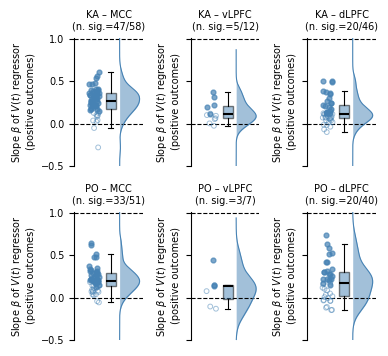

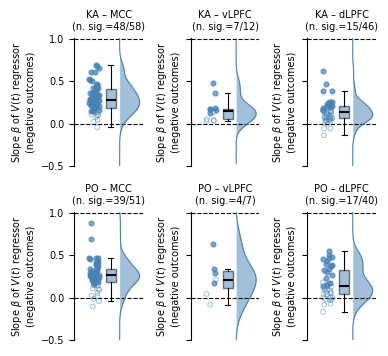

In [6]:
plot_betas(res_df)

In [7]:
# Export source data (Supplementary Figure 10a, 10b)
from popy.source_data import export_source_data
from matplotlib.cbook import boxplot_stats  # the statistics drawn by ax.boxplot

# values plotted by plot_betas(): one dot per session (filled: 95% CI of the slope within [0, 1]), box plot and half violin
# (kernel density estimate) of the same values, per monkey and area
slopes_sd = {'10a': ('slope_pos', 'slope_pos_withinbounds', 'rewarded (positive outcome)'),
             '10b': ('slope_neg', 'slope_neg_withinbounds', 'unrewarded (negative outcome)')}
for panel_sd, (var_sd, signif_col_sd, outcome_sd) in slopes_sd.items():
    sessions_sd, boxes_sd = [], []
    for monkey_sd in res_df['monkey'].unique():
        for area_sd in res_df['subregion'].unique():
            subset_sd = res_df[(res_df['monkey'] == monkey_sd) & (res_df['subregion'] == area_sd)]
            assert subset_sd[var_sd].notna().all() and subset_sd[signif_col_sd].notna().all()
            sessions_sd.append(pd.DataFrame({
                'Monkey': monkey_sd.upper(), 'Session': subset_sd['session'].values, 'Area': area_sd,
                f'Slope of V(t), {outcome_sd} trials': subset_sd[var_sd].values,
                'Significant (filled dot; 95% CI of the slope within [0, 1])': subset_sd[signif_col_sd].values.astype(bool)}))
            box_sd = boxplot_stats(subset_sd[var_sd].values)[0]
            boxes_sd.append({'Monkey': monkey_sd.upper(), 'Area': area_sd, 'n sessions': len(subset_sd),
                             'n significant sessions': int(subset_sd[signif_col_sd].sum()),
                             'Median': box_sd['med'], 'Q1': box_sd['q1'], 'Q3': box_sd['q3'],
                             'Lower whisker': box_sd['whislo'], 'Upper whisker': box_sd['whishi']})
    sessions_sd = pd.concat(sessions_sd, ignore_index=True)
    n_sessions_sd = '; '.join(f'{b["Monkey"]} {b["Area"]}: n = {b["n sessions"]}' for b in boxes_sd)
    export_source_data(
        f'Supplementary Figure {panel_sd}',
        {'Dots: sessions': sessions_sd, 'Box plots (of the sessions)': pd.DataFrame(boxes_sd)},
        f'Slope of the V(t) regressor for {outcome_sd} trials t (beta1 for unrewarded, beta1 + beta3 for rewarded trials) in the '
        'linear regression V(t+1) = beta0 + beta1 V(t) + beta2 R + beta3 V(t) R of each session (V: neural value of the task '
        f'engagement period, {time_interval[0]}-{time_interval[1]} s of the time-normalized trial, z-scored within session; R: outcome '
        f'of trial t, 1: rewarded), per monkey and area ({n_sessions_sd} sessions). Dots: sessions (the horizontal jitter is not '
        'exported); filled dots: sessions whose 95% confidence interval of the slope is within [0, 1] (n. sig. in the titles). Box '
        'plots: median, quartiles (Q1, Q3) and whiskers (most extreme values within 1.5 x IQR of the quartiles), outliers not drawn '
        'separately; half violins: kernel density estimates of the same values. Dashed lines: 0 and 1.')

Supplementary Figure 10a: source data saved (214 rows, 6 rows)
Supplementary Figure 10b: source data saved (214 rows, 6 rows)


---
# Supplementary Fig. 10c, Intercept difference

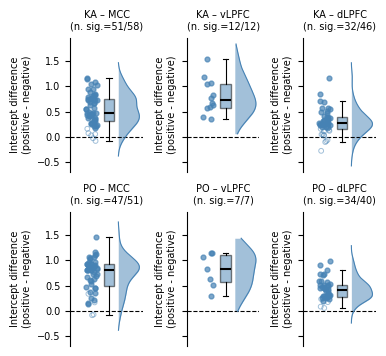

In [8]:
plot_intercept_differences(res_df)

In [9]:
# Export source data (Supplementary Figure 10c)
from popy.source_data import export_source_data
from matplotlib.cbook import boxplot_stats  # the statistics drawn by ax.boxplot

# values plotted by plot_intercept_differences(): one dot per session (filled: intercept significantly higher for rewarded
# trials), box plot and half violin (kernel density estimate) of the same values, per monkey and area
sessions_10c, boxes_10c = [], []
for monkey_sd in res_df['monkey'].unique():
    for area_sd in res_df['subregion'].unique():
        subset_sd = res_df[(res_df['monkey'] == monkey_sd) & (res_df['subregion'] == area_sd)]
        diff_sd = (subset_sd['intercept_pos'] - subset_sd['intercept_neg']).values
        assert np.isfinite(diff_sd).all()
        sessions_10c.append(pd.DataFrame({
            'Monkey': monkey_sd.upper(), 'Session': subset_sd['session'].values, 'Area': area_sd,
            'Intercept difference (rewarded - unrewarded)': diff_sd,
            'Significant (filled dot; one-sided Wald test of beta2 > 0, p < 0.05)': subset_sd['intercept_pos_higher'].values.astype(bool)}))
        box_sd = boxplot_stats(diff_sd)[0]
        boxes_10c.append({'Monkey': monkey_sd.upper(), 'Area': area_sd, 'n sessions': len(subset_sd),
                          'n significant sessions': int(subset_sd['intercept_pos_higher'].sum()),
                          'Median': box_sd['med'], 'Q1': box_sd['q1'], 'Q3': box_sd['q3'],
                          'Lower whisker': box_sd['whislo'], 'Upper whisker': box_sd['whishi']})
sessions_10c = pd.concat(sessions_10c, ignore_index=True)
n_sessions_sd = '; '.join(f'{b["Monkey"]} {b["Area"]}: n = {b["n sessions"]}' for b in boxes_10c)
export_source_data(
    'Supplementary Figure 10c',
    {'Dots: sessions': sessions_10c, 'Box plots (of the sessions)': pd.DataFrame(boxes_10c)},
    'Difference between the intercepts for rewarded and unrewarded trials t (beta2) in the linear regression '
    'V(t+1) = beta0 + beta1 V(t) + beta2 R + beta3 V(t) R of each session (V: neural value of the task engagement period, '
    f'{time_interval[0]}-{time_interval[1]} s of the time-normalized trial, z-scored within session; R: outcome of trial t, 1: rewarded), '
    f'per monkey and area ({n_sessions_sd} sessions). Dots: sessions (the horizontal jitter is not exported); filled dots: sessions '
    'with a significantly higher intercept for rewarded trials (one-sided Wald test of beta2 > 0, p < 0.05; n. sig. in the titles). Box '
    'plots: median, quartiles (Q1, Q3) and whiskers (most extreme values within 1.5 x IQR of the quartiles), outliers not drawn '
    'separately; half violins: kernel density estimates of the same values. Dashed line: 0.')

Supplementary Figure 10c: source data saved (214 rows, 6 rows)
